# California Housing — MLP Regression Workshop
##Christina Chrysostomou (30470).
##Konstantinos Avramidis (27779).
##Florentia Chrysostomou (30297).
##Kyriakos Sourmelis (27676).
##Russell Vickramasingam (30713).

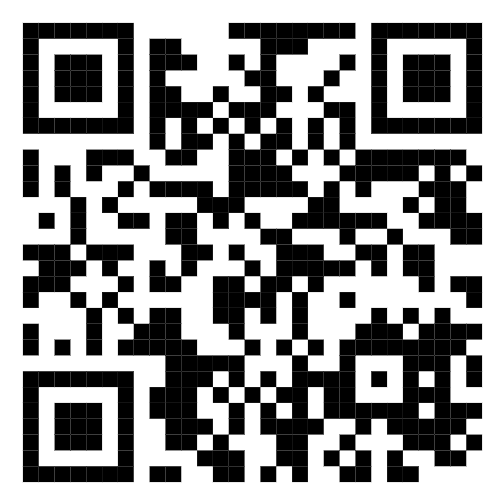

### Cell 1 — Setup and imports
Firstly, we load all the libraries that are needed.

In [42]:
# Uncomment the first line if there are libraries missing
# %pip install -q scikit-learn numpy pandas matplotlib

# General libraries
import numpy as np                       # Numerical calculations
import pandas as pd                      # Tables / DataFrames
import matplotlib.pyplot as plt         # Graphs
import warnings

# Tools we will use
from IPython.display import display
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# Hide the Convergence Warning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Fixed random seed, so everyone has the same results
SEED = 42

# Convert house values in dollars for printing purposes
USD = 100_000

print("Libraries loaded successfully")

Libraries loaded successfully


### Cell 2 — Load and inspect the dataset
We load the California Housing dataset and display the first 10 rows.
- Each row is a **neighbourhood (census block group)** from the 1990 census, not a single house
- `X` = the **8 input features** we give to the MLP
- `y` = the **target**: the median house value

In [43]:
# Load the dataset as Pandas tables
housing = fetch_california_housing(as_frame=True)

X = housing.data.copy()        # 8 input columns
y = housing.target.copy()      # Target: median

#Print number of rows (neighbourhoods) and columns (features)
print("Observations:", len(X))
print("Features:", X.shape[1])

#Display the first 10 rows
display(housing.frame.head(10))

Observations: 20640
Features: 8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


### Cell 3 — Training / validation / test split
We split the data into three parts, so we never judge the model on the same data it learned from:
- **Training (64%):** the model learns from this data
- **Validation (16%):** used to compare experiments and choose the best model
- **Test (20%):** kept hidden and used **only once**, at the very end

In [44]:
# Keep 20% for the final test and the rest for development
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

# Split the remaining 80% into training (64%) and validation (16%)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED
)

# Print the size and percentage of each set
print(f"Training:   {len(X_train):,} observations ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_val):,} observations ({len(X_val)/len(X):.0%})")
print(f"Testing:    {len(X_test):,} observations ({len(X_test)/len(X):.0%})")

Training:   13,209 observations (64%)
Validation: 3,303 observations (16%)
Testing:    4,128 observations (20%)


### Cell 4 — Why standardize the features?
The features have very different scales. Without scaling, the large numbers would dominate the MLP's learning.
- `StandardScaler` gives every feature **mean = 0** and **standard deviation = 1**
- It learns the mean and standard deviation **only from the training data**, to avoid data leakage
- Here we show a demo on `Population`; our real models do this automatically inside a `Pipeline`

In [45]:

# Create a scaler and learn the mean/std from the training data
scaler_demo = StandardScaler()

# Scale the training data & keep the column names and row numbers
X_train_scaled_demo = pd.DataFrame(
    scaler_demo.fit_transform(X_train),
    columns=X_train.columns, index=X_train.index
)

# Compare population before and after scaling
feature = "Population"
print("Original training Population (first 5):")
display(X_train[[feature]].head())
print("Standardized training Population (first 5):")
display(X_train_scaled_demo[[feature]].head().round(3))

# Check the result. Mean should be 0 and standard deviation 1
print("Mean after scaling:", round(X_train_scaled_demo[feature].mean(), 5))
print("Std after scaling:", round(X_train_scaled_demo[feature].std(ddof=0), 5))

Original training Population (first 5):


,Population
16490,873.0
6090,3359.0
10973,1273.0
17287,705.0
12615,1857.0


Standardized training Population (first 5):


,Population
16490,-0.487
6090,1.699
10973,-0.135
17287,-0.635
12615,0.378


Mean after scaling: 0.0
Std after scaling: 1.0


---
- MLP is fully connected: every neuron connects to the next layer
- `fit()` repeats: predict → loss → gradients → update

### Cell 5 — Reusable MLP creator
Using a function lets us **change one parameter at a time** during experiments. The `Pipeline` standardizes inputs automatically. `MLPRegressor` has a **linear output** for regression.

In [46]:
def make_model(layers=(32, 16), activation="relu", solver="adam",
               max_iter=200, learning_rate_init=0.001,
               early_stopping=False, alpha=0.0001, seed=SEED):
    # Fully connected MLP + automatic feature standardization
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=layers,       # Neurons in each hidden layer
            activation=activation,          # Hidden activation: relu/tanh/logistic
            solver=solver,                  # Optimizer: adam/sgd/lbfgs
            max_iter=max_iter,              # Max epochs when using Adam/SGD
            learning_rate_init=learning_rate_init,
            early_stopping=early_stopping,  # Monitor internal validation R² if True
            n_iter_no_change=12, tol=1e-4,
            alpha=alpha, random_state=seed
        ))
    ])

def scores(y_true, y_pred):
    return {
        "MAE ($)": mean_absolute_error(y_true, y_pred) * USD,
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)) * USD,
        "R²": r2_score(y_true, y_pred)
    }

print("Model creator and evaluation function are ready")

Model creator and evaluation function are ready


### Cell 6 — Architecture and train
- 8 inputs → 32 (ReLU) → 16 (ReLU) → 1 (linear output)
- 784 weights + 49 biases = **833** parameters
- Ask: parameters of (64, 32)? → **2,689**
- One epoch ≈ 67 weight updates
- `random_state=42` = reproducible, not a weight value

In [47]:
baseline = make_model(layers=(32, 16), activation="relu",
                      solver="adam", max_iter=200)
baseline.fit(X_train, y_train)           # This is where training occurs!
mlp = baseline.named_steps["mlp"]

print("Hidden layers:", mlp.hidden_layer_sizes)
print("Weight matrix shapes:", [w.shape for w in mlp.coefs_])   # (8,32), (32,16), (16,1)
print("Output activation:", mlp.out_activation_)               # 'identity' = linear output
print("Epochs completed:", mlp.n_iter_, "of max", mlp.max_iter)
if mlp.n_iter_ >= mlp.max_iter:
    print("-> Reached the epoch limit (loss may still have been improving).")
else:
    print("-> Stopped early: loss improved less than tol for", mlp.n_iter_no_change, "epochs in a row.")
print("Final training loss:", round(mlp.loss_, 5))
print("Weights:", sum(w.size for w in mlp.coefs_))
print("Biases:", sum(b.size for b in mlp.intercepts_))

Hidden layers: (32, 16)
Weight matrix shapes: [(8, 32), (32, 16), (16, 1)]
Output activation: identity
Epochs completed: 200 of max 200
-> Reached the epoch limit (loss may still have been improving).
Final training loss: 0.13193
Weights: 784
Biases: 49


### Cell 6b — Forward pass by hand
- Recompute one prediction with NumPy
- Compare with `predict()`: they must match

In [48]:
row = X_train.iloc[[0]]                                   # one real observation
x  = baseline.named_steps["scaler"].transform(row)        # step 0: standardize
h1 = np.maximum(0, x  @ mlp.coefs_[0] + mlp.intercepts_[0])   # hidden layer 1 + ReLU
h2 = np.maximum(0, h1 @ mlp.coefs_[1] + mlp.intercepts_[1])   # hidden layer 2 + ReLU
out = h2 @ mlp.coefs_[2] + mlp.intercepts_[2]                  # linear output

print("Manual forward pass : $", round(out[0, 0] * USD))
print("model.predict()     : $", round(baseline.predict(row)[0] * USD))
print("Actual value        : $", round(y_train.iloc[0] * USD))
print("Same result?", np.isclose(out[0, 0], baseline.predict(row)[0]))

Manual forward pass : $ 147196
model.predict()     : $ 147196
Actual value        : $ 176900
Same result? True


### Cell 7 — Training-loss curve
- Epoch = one full pass over the training data
- Falling loss ≠ good validation performance
- Loss is not in dollars: RMSE ≈ √(2 × loss) × $100,000
- Log axis: most improvement is in the first epochs

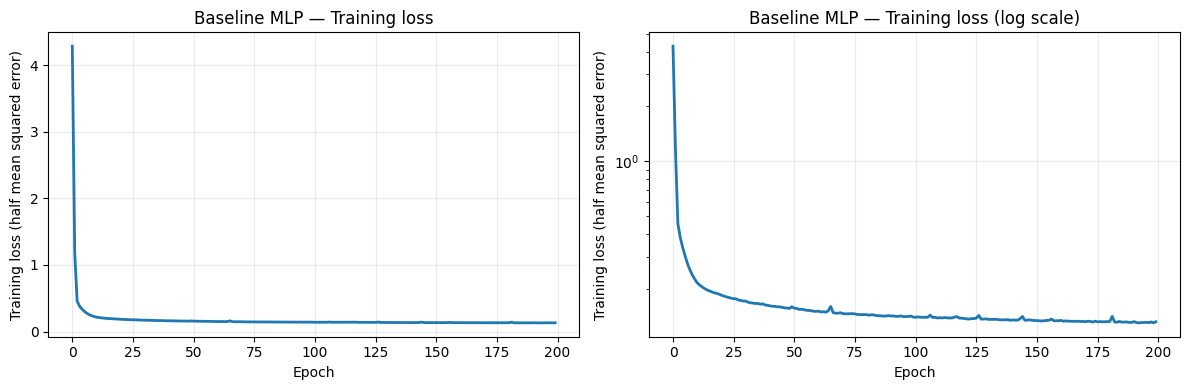

Approx. training RMSE implied by the final loss: $ 51367


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, log in zip(axes, [False, True]):
    ax.plot(mlp.loss_curve_, linewidth=2)
    ax.set_title("Baseline MLP — Training loss" + (" (log scale)" if log else ""))
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss (half mean squared error)")
    if log:
        ax.set_yscale("log")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Approx. training RMSE implied by the final loss: $", round(np.sqrt(2 * mlp.loss_) * USD))

**Wrap-up:**
- Forward pass → loss → backprop gradients → Adam update
- Stops at `max_iter`, or when progress < `tol` for `n_iter_no_change` epochs
- Warnings are hidden: check `n_iter_`

### Cell 7b — (Optional) Stop too early
- Same network, only 5 epochs
- Compare with the baseline

In [50]:
short = make_model(layers=(32, 16), max_iter=5)
short.fit(X_train, y_train)
print("5 epochs  — validation:", {k: round(v, 3) for k, v in scores(y_val, short.predict(X_val)).items()})
print("Baseline  — validation:", {k: round(v, 3) for k, v in scores(y_val, baseline.predict(X_val)).items()})

5 epochs  — validation: {'MAE ($)': 58648.864, 'RMSE ($)': np.float64(81649.431), 'R²': 0.517}
Baseline  — validation: {'MAE ($)': 38133.28, 'RMSE ($)': np.float64(57480.507), 'R²': 0.761}


### Cell 8 — Validation metrics and comparison with training
The model has already been trained. Now we give it two different datasets:
*   **Training data:** Data it used to learn
*   **Validation data:** Data it did not use to learn

We ask it to make predictions and then compare those predictions with the real values to find out how good our model is.



In [51]:
# Generate predictions for training and validation data
train_pred = baseline.predict(X_train)
val_pred = baseline.predict(X_val)

# Compare the model's performance on both datasets
comparison = pd.DataFrame([
    {"Dataset": "Training", **scores(y_train, train_pred)},
    {"Dataset": "Validation", **scores(y_val, val_pred)},
]).set_index("Dataset")

# Display MAE, RMSE and R²
display(comparison.round(3))

,MAE ($),RMSE ($),R²
Dataset,,,
Training,34661.486,50708.100,0.806
Validation,38133.280,57480.507,0.761


### Cell 9 — First 10 real validation predictions
Now we want to see individual predictions, instead of only seeing how much the model makes mistakes on average.

In [52]:
# Create a table with actual and predicted house values
prediction_table = pd.DataFrame({
    "Actual ($)": y_val.to_numpy() * USD,
    "Predicted ($)": val_pred * USD
})

#We create a third column called Absolute error
# Calculate the absolute prediction error
prediction_table["Absolute error ($)"] = (
    prediction_table["Predicted ($)"] - prediction_table["Actual ($)"]
).abs()

#Display the first 10 predictions
display(prediction_table.head(10).round(0))

# Display the sixth actual and predicted values as an example
print("6th validation actual:   $", round(y_val.iloc[5] * USD))
print("6th validation predicted:$", round(val_pred[5] * USD))

,Actual ($),Predicted ($),Absolute error ($)
0,96700.0,120301.0,23601.0
1,75500.0,82769.0,7269.0
2,430900.0,238906.0,191994.0
3,332600.0,252310.0,80290.0
4,500001.0,437300.0,62701.0
5,137900.0,145780.0,7880.0
6,179600.0,175206.0,4394.0
7,95700.0,90484.0,5216.0
8,170800.0,245057.0,74257.0
9,42500.0,44932.0,2432.0


6th validation actual:   $ 137900
6th validation predicted:$ 145780


### Cell 10 — Actual vs predicted and biggest mistakes
Dots on the dashed diagonal are perfect predictions; above = overestimation, below = underestimation. The dataset's recorded target values are capped around **$500,000**, creating a vertical cluster near that value.

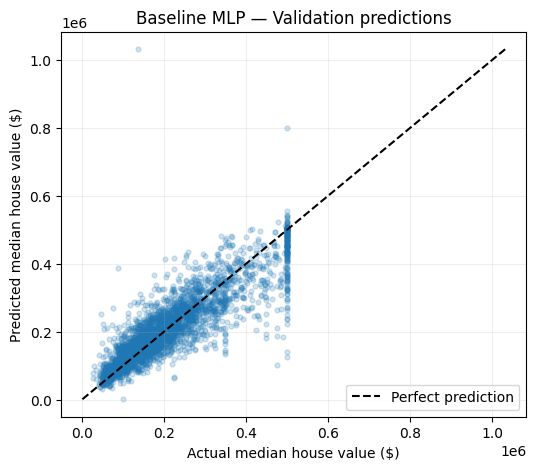

5 largest absolute validation errors:


,Actual ($),Predicted ($),Absolute error ($)
2139,137500.0,1032051.0,894551.0
2380,475000.0,101768.0,373232.0
585,500001.0,126907.0,373094.0
2101,500001.0,140226.0,359775.0
29,489600.0,183762.0,305838.0


In [53]:
# Create a scatter plot comparing actual and predicted values
plt.figure(figsize=(6, 5))

#Each dot represents one validation observation
plt.scatter(y_val.to_numpy() * USD, val_pred * USD,
            alpha=0.20, s=12)

# Find the minimum and maximum values for the diagonal line
lo = min((y_val.min() * USD), (val_pred.min() * USD))
hi = max((y_val.max() * USD), (val_pred.max() * USD))

#Draw the perfect prediction line (Actual = Predicted)
plt.plot([lo, hi], [lo, hi], "k--", label="Perfect prediction")

#Add labels, title and legend
plt.xlabel("Actual median house value ($)")
plt.ylabel("Predicted median house value ($)")
plt.title("Baseline MLP — Validation predictions")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Find the 5 observations with the largest prediction errors
print("5 largest absolute validation errors:")
display(prediction_table.nlargest(5, "Absolute error ($)").round(0))

### Cell 11 — Compare architectures (neurons and layers)
## Experiment 1: Comparing MLP Architectures

We train **7 different MLP architectures** using the same training data. Each MLP has a different number of hidden layers and neurons.

We compare their predictions using **validation data** and select the architecture with the **lowest RMSE**.


,Architecture,Total hidden neurons,Parameters,Epochs,MAE ($),RMSE ($),R²
4,"(128, 64)",192,9473,200,35410.05,52398.39,0.80
3,"(64, 32)",96,2689,200,35921.75,52941.62,0.80
5,"(256, 128)",384,35329,200,35295.17,53040.05,0.80
2,"(32, 16)",48,833,200,38133.28,57480.51,0.76
1,"(16,)",16,161,200,40481.10,58863.89,0.75
0,"(8,)",8,81,200,43462.69,61927.28,0.72


Best architecture among those tested: (128, 64)


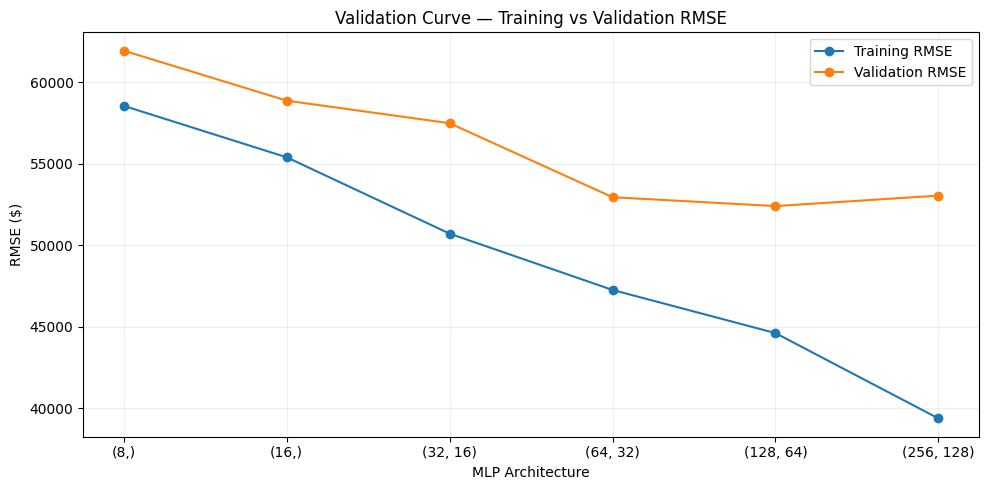

In [54]:
# 1. Define the architectures we want to test
# Each tuple represents the number of neurons in each hidden layer
architectures = [(8,), (16,), (32, 16),
                 (64, 32), (128, 64), (256, 128)]

architecture_models = {}
results = []

# Lists to store training and validation RMSE for plotting
train_rmse_values = []
val_rmse_values = []


# 2. Train and evaluate each architecture
for arch in architectures:

    # Create an MLP model with the current architecture
    model = make_model(layers=arch)

    # Train the model using the training dataset
    model.fit(X_train, y_train)

    # Save the trained model in the dictionary
    # The architecture tuple is used as the key
    architecture_models[arch] = model

    val_predictions = model.predict(X_val)

    train_predictions = model.predict(X_train)

    train_rmse = scores(y_train, train_predictions)["RMSE ($)"]

    val_rmse = scores(y_val, val_predictions)["RMSE ($)"]

    # Store RMSE values for the graph
    train_rmse_values.append(train_rmse)
    val_rmse_values.append(val_rmse)

    # Access the MLP model inside the pipeline
    mlp = model.named_steps["mlp"]

    # Store information about the current architecture
    results.append({
        "Architecture": str(arch),
        "Total hidden neurons": sum(arch),
        "Parameters": sum(w.size for w in mlp.coefs_) +
                      sum(b.size for b in mlp.intercepts_),
        "Epochs": mlp.n_iter_,
        **scores(y_val, val_predictions)
    })


# 3. Display the results, sorted by lowest RMSE

# Convert the results list into a Pandas DataFrame
# Sort models by validation RMSE (lowest error first)
architecture_results = pd.DataFrame(results).sort_values("RMSE ($)")

# Display results rounded to 2 decimal places
display(architecture_results.round(2))


# 4. Find the best architecture

# Select the architecture from the first row
best_name = architecture_results.iloc[0]["Architecture"]

# Find the original tuple corresponding to the best architecture
best_architecture = next(
    arch for arch in architectures if str(arch) == best_name
)

# Print the architecture with the lowest validation RMSE
print("Best architecture among those tested:", best_architecture)


# 5. Plot the training and validation RMSE

# Create a figure with width 10 and height 5
plt.figure(figsize=(10, 5))

# Plot training RMSE for each architecture
plt.plot(
    range(len(architectures)),  # X-axis: architecture positions
    train_rmse_values,          # Y-axis: training RMSE values
    marker="o",                 # Display a circle at each point
    label="Training RMSE"       # Label used in the legend
)

# Plot validation RMSE for each architecture
plt.plot(
    range(len(architectures)),  # X-axis: architecture positions
    val_rmse_values,            # Y-axis: validation RMSE values
    marker="o",
    label="Validation RMSE"
)

# Replace numerical X-axis positions with architecture names
plt.xticks(
    range(len(architectures)),
    [str(arch) for arch in architectures]
)

plt.xlabel("MLP Architecture")
plt.ylabel("RMSE ($)")
plt.title("Validation Curve — Training vs Validation RMSE")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

###Cell 12 — Experiment 2: Comparing Activation Functions
## Experiment 2: Comparing Activation Functions

We train **3 different MLPs** using the same training data and architecture `(32, 16)`, but with different activation functions: **ReLU, Tanh, and Sigmoid (Logistic)**.

We compare their predictions using **validation data** and identify the activation function with the **lowest RMSE**.

**What is the purpose of activation functions?**

Activation functions help the MLP learn complex relationships between inputs and outputs.

- **ReLU:** Converts negative values to zero and keeps positive values unchanged.
- **Tanh:** Produces values between -1 and 1.
- **Sigmoid (Logistic):** Produces values between 0 and 1.


,Activation,MAE ($),RMSE ($),R²
0,tanh,37160.91,54231.78,0.79
1,relu,38133.28,57480.51,0.76
2,logistic,41820.21,59748.71,0.74


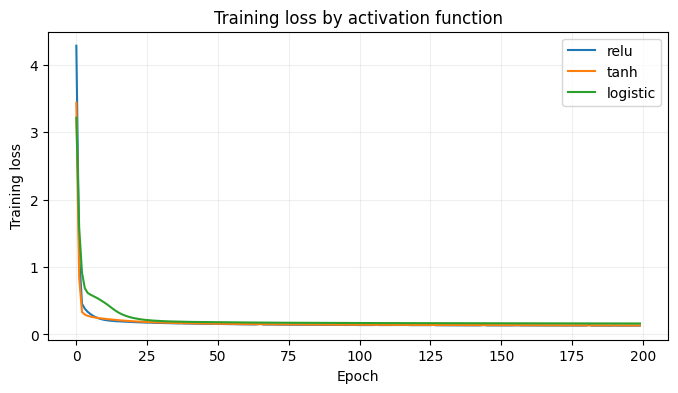

In [61]:
# 1. Choose the activation functions
activations = ["relu", "tanh", "logistic"]

results = {}
activation_models = {}

# 2. Train and evaluate each activation function
for activation in activations:

    model = make_model(layers=(32,16),activation=activation)
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    results[activation] = scores(y_val, predictions)
    activation_models[activation] = model

# 3. Compare the results
activation_results = pd.DataFrame(results).T.sort_values("RMSE ($)")
activation_results.index.name = "Activation"

display(activation_results.reset_index().round(2))

# 4. Compare training loss
plt.figure(figsize=(8, 4))

for activation in activations:
    plt.plot(activation_models[activation].named_steps["mlp"].loss_curve_, label=activation)

plt.title("Training loss by activation function")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

###Cell 13 — Experiment 3: Comparing Optimizers
## Experiment 3: Comparing Optimizers

We train **2 different MLPs** using the same training data and architecture `(32, 16)`, but with different optimizers: **Adam and SGD**.

We compare their predictions using **validation data** and identify the optimizer with the **lowest RMSE**.

**What is the purpose of an optimizer?**

An optimizer updates the MLP's **weights and biases** during training to reduce prediction errors.

- **Adam:** Automatically adjusts the learning updates for each weight and bias, often making training faster and easier.
- **SGD (Stochastic Gradient Descent):** Updates weights and biases using gradients and a learning rate. It may require more tuning.


In [56]:
# 1. Choose the optimizers
optimizers = ["adam", "sgd"]

results = []
optimizer_models = {}

# 2. Train and evaluate each optimizer
for optimizer in optimizers:

    model = make_model(
        layers=(32,16),
        solver=optimizer
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    optimizer_models[optimizer] = model

    results.append({
        "Optimizer": optimizer,
        "Epochs": model.named_steps["mlp"].n_iter_,
        **scores(y_val, predictions)
    })

# 3. Compare the results
optimizer_results = pd.DataFrame(results).sort_values("RMSE ($)")

display(optimizer_results.round(2))

,Optimizer,Epochs,MAE ($),RMSE ($),R²
0,adam,200,38133.28,57480.51,0.76
1,sgd,200,41799.46,59082.86,0.75


### Cell 14 — Training settings and stopping criteria
First, we will examine four different training experiments.

In the code, we will notice that we change:

- The number of epochs.
- The learning rate.
- The use of early stopping.

The code trains one model for each different configuration and calculates MAE, RMSE, and R².

At the end, a table is displayed comparing the results. This allows us to see which configuration achieved the best performance.

**max_iter:** Determines the maximum number of training iterations (epochs) the model can perform.

**learning_rate_init:** Determines how large the weight updates are during training.

**early_stopping=True:** The model checks whether its performance is improving using a portion of the training data reserved for validation. If performance stops improving, training stops early.

**X_val:** This is the validation dataset that we use to compare the different models and identify which one performs best.First, we will examine four different training experiments.

In [57]:
settings = [
    {"label": "50 epochs", "max_iter": 50, "learning_rate_init": 0.001, "early_stopping": False},
    {"label": "200 epochs", "max_iter": 200, "learning_rate_init": 0.001, "early_stopping": False},
    {"label": "Higher learning rate", "max_iter": 200, "learning_rate_init": 0.01, "early_stopping": False},
    {"label": "Early stopping", "max_iter": 200, "learning_rate_init": 0.001, "early_stopping": True},
]
settings_rows = []
for setting in settings:
    cand = make_model(layers=(32, 16), max_iter=setting["max_iter"],
                      learning_rate_init=setting["learning_rate_init"],
                      early_stopping=setting["early_stopping"])
    cand.fit(X_train, y_train)
    settings_rows.append({"Setting": setting["label"],
                          "Epochs completed": cand.named_steps["mlp"].n_iter_,
                          **scores(y_val, cand.predict(X_val))})
settings_results = pd.DataFrame(settings_rows).sort_values("RMSE ($)")
display(settings_results.round(2))

,Setting,Epochs completed,MAE ($),RMSE ($),R²
2,Higher learning rate,119,36249.02,54275.86,0.79
1,200 epochs,200,38133.28,57480.51,0.76
3,Early stopping,143,39256.81,58139.36,0.76
0,50 epochs,50,40781.05,58593.17,0.75


### Cell 15 — Underfitting demonstration
Next, we will examine the phenomenon of underfitting.

For this experiment, we create a very small neural network with only one neuron in the hidden layer.

We compare it with our baseline model, which has two hidden layers with 32 and 16 neurons.

In [58]:
underfit = make_model(layers=(1,), max_iter=180)
underfit.fit(X_train, y_train)
underfit_table = pd.DataFrame([
    {"Architecture": "(1,) — small", "Training RMSE ($)": scores(y_train, underfit.predict(X_train))["RMSE ($)"],
     "Validation RMSE ($)": scores(y_val, underfit.predict(X_val))["RMSE ($)"]},
    {"Architecture": "(32,16) — baseline", "Training RMSE ($)": scores(y_train, baseline.predict(X_train))["RMSE ($)"],
     "Validation RMSE ($)": scores(y_val, baseline.predict(X_val))["RMSE ($)"]}
])
display(underfit_table.round(0))

,Architecture,Training RMSE ($),Validation RMSE ($)
0,"(1,) — small",67861.0,69434.0
1,"(32,16) — baseline",50708.0,57481.0


### Cell 16 — Overfitting demonstration (separate educational experiment)
In this cell, we will examine the opposite phenomenon, which is overfitting.

We create a larger neural network and use only 120 observations to train it. We also add a small amount of random noise to the training target values.

We train the model for 180 epochs, and at each epoch, we calculate the error on both the training and validation datasets.

Best epoch by validation RMSE: 1
RMSE at final epoch — noisy train: $ 31365
RMSE at final epoch — clean validation: $ 728249


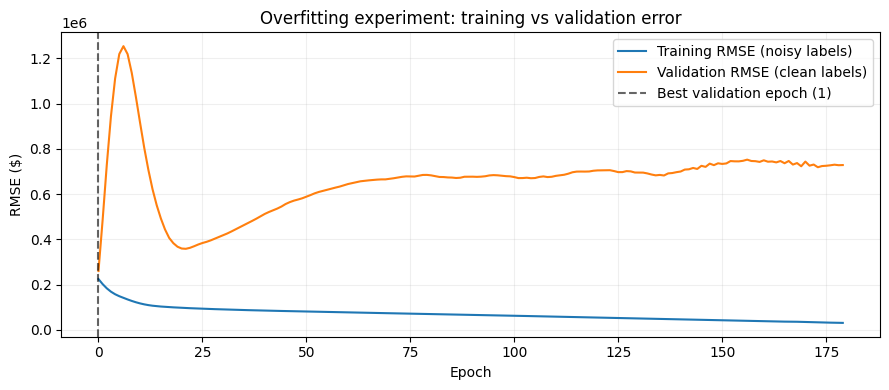

In [59]:
rng = np.random.default_rng(SEED)
small_positions = rng.choice(len(X_train), size=120, replace=False)
X_small = X_train.iloc[small_positions]
y_small_clean = y_train.iloc[small_positions].to_numpy()
y_small_noisy = y_small_clean + rng.normal(0, 0.65, size=len(y_small_clean))

# Fit scaling only on this small, noisy-training experiment's training features
small_scaler = StandardScaler().fit(X_small)
small_X_scaled = small_scaler.transform(X_small)
clean_val_scaled = small_scaler.transform(X_val)

large = MLPRegressor(hidden_layer_sizes=(128, 64), activation="relu",
                     solver="adam", batch_size=32, alpha=0.000001,
                     random_state=SEED)
train_rmse_history = []
val_rmse_history = []
for epoch in range(180):
    large.partial_fit(small_X_scaled, y_small_noisy)  # One more epoch, weights retained
    train_rmse_history.append(
        np.sqrt(mean_squared_error(y_small_noisy, large.predict(small_X_scaled))) * USD
    )
    val_rmse_history.append(
        np.sqrt(mean_squared_error(y_val, large.predict(clean_val_scaled))) * USD
    )

best_epoch = int(np.argmin(val_rmse_history)) + 1
print("Best epoch by validation RMSE:", best_epoch)
print("RMSE at final epoch — noisy train: $", round(train_rmse_history[-1]))
print("RMSE at final epoch — clean validation: $", round(val_rmse_history[-1]))
plt.figure(figsize=(9, 4))
plt.plot(train_rmse_history, label="Training RMSE (noisy labels)")
plt.plot(val_rmse_history, label="Validation RMSE (clean labels)")
plt.axvline(best_epoch - 1, linestyle="--", color="black", alpha=0.6,
            label=f"Best validation epoch ({best_epoch})")
plt.title("Overfitting experiment: training vs validation error")
plt.xlabel("Epoch")
plt.ylabel("RMSE ($)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Cell 17 — Choose the best model from the combined architecture × activation search
At this point, we test different combinations of neural network architectures and activation functions.

Specifically, we have seven different architectures and three activation functions: ReLU, Tanh, and Logistic.

This gives us a total of 21 different combinations.

For each combination, we calculate MAE, RMSE, and R² using the validation dataset.

In [62]:
search_results = []
for arch in architectures:
    for activation in ["relu", "tanh", "logistic"]:
        # Already evaluated the ReLU architecture candidates above; reuse their models
        # The separate activation experiment already includes (32,16) for each activation.
        if activation == "relu":
            candidate = architecture_models[arch]
        elif arch == (32, 16):
            candidate = activation_models[activation]
        else:
            candidate = make_model(layers=arch, activation=activation, max_iter=160)
            candidate.fit(X_train, y_train)
        metrics = scores(y_val, candidate.predict(X_val))
        search_results.append({"Architecture": arch,
                               "Activation": activation,
                               "Validation RMSE ($)": metrics["RMSE ($)"],
                               "Validation MAE ($)": metrics["MAE ($)"],
                               "Validation R²": metrics["R²"]})
search_table = pd.DataFrame(search_results).sort_values("Validation RMSE ($)").reset_index(drop=True)
display(search_table.head(10).round(2))
best_layers = search_table.loc[0, "Architecture"]
best_activation = search_table.loc[0, "Activation"]
print("BEST AMONG TESTED: layers =", best_layers, "| activation =", best_activation)
print("Validation RMSE: $", round(search_table.loc[0, "Validation RMSE ($)"]))

,Architecture,Activation,Validation RMSE ($),Validation MAE ($),Validation R²
0,"(128, 64)",relu,52398.39,35410.05,0.80
1,"(128, 64)",tanh,52808.01,35609.26,0.80
2,"(64, 32)",relu,52941.62,35921.75,0.80
3,"(256, 128)",tanh,53013.24,35716.66,0.80
4,"(256, 128)",relu,53040.05,35295.17,0.80
5,"(64, 32)",tanh,53360.36,36389.08,0.79
6,"(32, 16)",tanh,54231.78,37160.91,0.79
7,"(32, 16)",relu,57480.51,38133.28,0.76
8,"(256, 128)",logistic,58648.56,40598.03,0.75
9,"(16,)",relu,58863.89,40481.10,0.75


BEST AMONG TESTED: layers = (128, 64) | activation = relu
Validation RMSE: $ 52398


### Cell 18 — Final model and unseen **test** evaluation
In the final cell, we create the final neural network using the best settings we selected earlier.

We train the model using both the training and validation datasets together.

Then, we evaluate it on the test set, which contains data that the model has never used during training or model selection.

In [63]:
final_model = make_model(layers=best_layers, activation=best_activation,
                         solver="adam", max_iter=160)
final_model.fit(X_dev, y_dev)              # 80% development data
final_test_pred = final_model.predict(X_test)  # First final test evaluation

print("Selected layers:", best_layers)
print("Selected hidden activation:", best_activation)
print("Final training epochs:", final_model.named_steps["mlp"].n_iter_)
print("FINAL HELD-OUT TEST PERFORMANCE:")
display(pd.DataFrame([scores(y_test, final_test_pred)]).round(3))

final_examples = pd.DataFrame({
    "Actual ($)": y_test.to_numpy()[:10] * USD,
    "Predicted ($)": final_test_pred[:10] * USD
})
final_examples["Absolute error ($)"] = abs(final_examples["Actual ($)"] - final_examples["Predicted ($)"])
display(final_examples.round(0))

Selected layers: (128, 64)
Selected hidden activation: relu
Final training epochs: 160
FINAL HELD-OUT TEST PERFORMANCE:


,MAE ($),RMSE ($),R²
0,34845.287,50915.191,0.802


,Actual ($),Predicted ($),Absolute error ($)
0,47700.0,50619.0,2919.0
1,45800.0,83450.0,37650.0
2,500001.0,503291.0,3290.0
3,218600.0,255147.0,36547.0
4,278000.0,244854.0,33146.0
5,158700.0,167929.0,9229.0
6,198200.0,246884.0,48684.0
7,157500.0,170016.0,12516.0
8,340000.0,250683.0,89317.0
9,446600.0,469823.0,23223.0
